# code_119 · Coordinate transformations and an unrolled graph solver

**Book:** section 23.5. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_119).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2519;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2519


<a id="geometric-physics-contract"></a>
 ## Rotate the loads and geometry under the same convention
 Generate sixty eight-node grounded isotropic spring graphs, with ring/chord connectivity, distance-dependent positive scalar stiffness and positive ground tethers. The dimensionless equilibrium is (L_k + diag(g)) u = F independently in each vector coordinate. This is an ideal isotropic network, not a frame-bending solver or a structural assessment. Exact linear solves give targets. Compare a coordinate-feature MLP, eight fixed Jacobi steps (relaxation one), and eight unrolled graph steps with learned sigmoid relaxation coefficients. The latter explicitly knows the physical operator and is an algorithm-unrolling graph model, not a full EGNN reproduction or a generic data-only architecture. Whole-building split 40/10/10; two rates and 300 updates per learned family, own development checkpoint. Test frozen predictions, equilibrium residuals and joint rotations/reflections/translations. The fixed numerical method is retained even when it beats the learned stepper.


,model,development_MSE,final_vector_MSE,final_equilibrium_residual_MSE,rotation_equivariance_RMS,reflection_equivariance_RMS,translation_response_RMS,parameters
0,Coordinate MLP,0.082387,0.090979,0.218251,1.179976e-01,0.150239,1.586472e-01,242
1,Fixed Jacobi,0.003403,0.004630,0.001309,1.558814e-16,0.000000,1.152312e-16,0
2,Learned graph steps,0.003631,0.004929,0.001291,1.676274e-16,0.000000,1.443899e-16,8


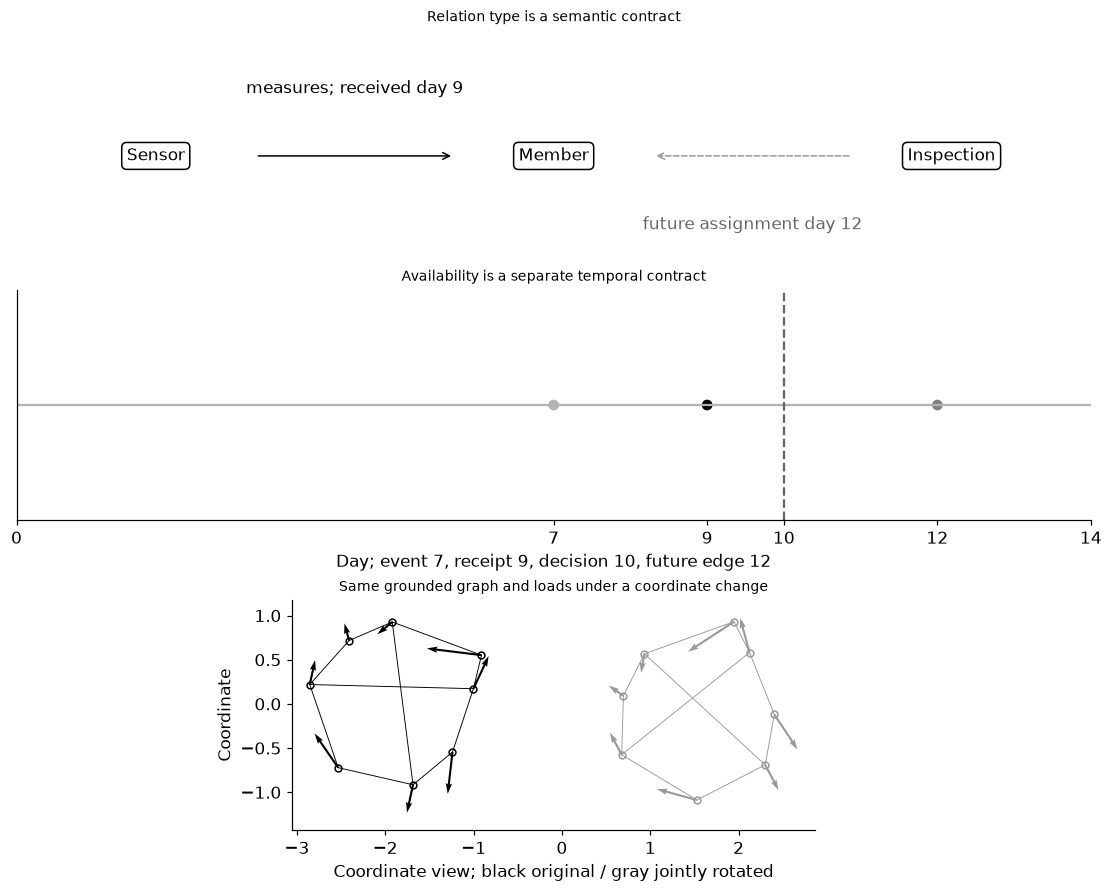

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
B,N=60,8;angle=np.arange(N)*2*np.pi/N;base=np.c_[np.cos(angle),np.sin(angle)];coordinates=base[None]+rng.normal(0,.15,(B,N,2));topology=np.zeros((B,N,N))
for b in range(B):
    for i in range(N):topology[b,i,(i+1)%N]=topology[b,(i+1)%N,i]=1
    for i,j in [(0,4),(2,6)]:topology[b,i,j]=topology[b,j,i]=1
ground=rng.uniform(.3,.8,(B,N));loads=rng.normal(size=(B,N,2))
def operator(coords):
    distance2=np.sum((coords[:,:,None,:]-coords[:,None,:,:])**2,axis=-1);stiffness=topology*np.exp(-distance2/2);diagonal=stiffness.sum(-1)+ground;matrix=-stiffness.copy();matrix[:,np.arange(N),np.arange(N)]=diagonal;return matrix,stiffness
matrix,stiffness=operator(coordinates);target=np.linalg.solve(matrix,loads);np.testing.assert_allclose(matrix@target,loads,atol=1e-12);assert np.linalg.eigvalsh(matrix).min()>0
laplacian=matrix.copy();laplacian[:,np.arange(N),np.arange(N)]-=ground;np.testing.assert_allclose((laplacian@target).sum(1),0,atol=1e-12);np.testing.assert_allclose(np.sum(ground[:,:,None]*target,axis=1),loads.sum(1),atol=1e-12)
f=torch.tensor(loads);a=torch.tensor(matrix);y=torch.tensor(target)
def raw_features(coords,forces,mat,weights):
    neighbor=weights@forces/weights.sum(-1,keepdims=True);return np.concatenate([coords,forces,neighbor,np.diagonal(mat,axis1=-2,axis2=-1)[:,:,None]],axis=-1)
raw=raw_features(coordinates,loads,matrix,stiffness);scaler=StandardScaler().fit(raw[:40].reshape(-1,7));x=torch.tensor(scaler.transform(raw.reshape(-1,7)).reshape(B,N,7))
class UnrolledGraph(nn.Module):
    def __init__(self):super().__init__();self.relaxation_logits=nn.Parameter(torch.zeros(8))
    def forward(self,force,mat):
        state=torch.zeros_like(force);diagonal=mat.diagonal(dim1=-2,dim2=-1).unsqueeze(-1)
        for eta in self.relaxation_logits.sigmoid():state=state+eta*(force-mat@state)/diagonal
        return state
def fixed_jacobi(force,mat):
    state=torch.zeros_like(force);diagonal=mat.diagonal(dim1=-2,dim2=-1).unsqueeze(-1)
    for step in range(8):state=state+(force-mat@state)/diagonal
    return state
class CoordinateMLP(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(7,24),nn.Tanh(),nn.Linear(24,2))
    def forward(self,h):return self.net(h)
fitted={};candidates=[]
for name,constructor,rates in [('Coordinate MLP',CoordinateMLP,[.005,.01]),('Learned graph steps',UnrolledGraph,[.03,.1])]:
    best_family=np.inf
    for rate in rates:
        torch.manual_seed(SEED);model=constructor();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=0);best=np.inf
        for step in range(1,301):
            optimizer.zero_grad();prediction=model(x) if name=='Coordinate MLP' else model(f,a);loss=torch.mean((prediction[:40]-y[:40])**2);loss.backward();optimizer.step()
            if step%10==0:
                with torch.no_grad():prediction=model(x) if name=='Coordinate MLP' else model(f,a);score=float(torch.mean((prediction[40:50]-y[40:50])**2))
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'model':name,'rate':rate,'development_MSE':best,'best_step':best_step})
        if best<best_family:best_family=best;chosen=(rate,best_step,state)
    rate,best_step,state=chosen;model.load_state_dict(state);model.eval();fitted[name]=model
def predict(name,coords,force):
    mat,weights=operator(coords)
    with torch.no_grad():
        if name=='Coordinate MLP':feat=raw_features(coords,force,mat,weights);return fitted[name](torch.tensor(scaler.transform(feat.reshape(-1,7)).reshape(B,N,7))).numpy()
        if name=='Learned graph steps':return fitted[name](torch.tensor(force),torch.tensor(mat)).numpy()
        return fixed_jacobi(torch.tensor(force),torch.tensor(mat)).numpy()
rotation_angle=.7;rotation=np.array([[np.cos(rotation_angle),-np.sin(rotation_angle)],[np.sin(rotation_angle),np.cos(rotation_angle)]]);reflection=np.diag([-1.,1.]);rows=[];original_predictions={}
for name in ['Coordinate MLP','Fixed Jacobi','Learned graph steps']:
    prediction=predict(name,coordinates,loads);original_predictions[name]=prediction;rotated=predict(name,coordinates@rotation.T,loads@rotation.T);reflected=predict(name,coordinates@reflection.T,loads@reflection.T);translated=predict(name,coordinates+np.array([2.,-1.]),loads)
    row={'model':name,'development_MSE':float(np.mean((prediction[40:50]-target[40:50])**2)),'final_vector_MSE':float(np.mean((prediction[50:]-target[50:])**2)),'final_equilibrium_residual_MSE':float(np.mean((matrix[50:]@prediction[50:]-loads[50:])**2)),'rotation_equivariance_RMS':float(np.sqrt(np.mean((rotated[50:]-prediction[50:]@rotation.T)**2))),'reflection_equivariance_RMS':float(np.sqrt(np.mean((reflected[50:]-prediction[50:]@reflection.T)**2))),'translation_response_RMS':float(np.sqrt(np.mean((translated[50:]-prediction[50:])**2))),'parameters':0 if name=='Fixed Jacobi' else sum(t.numel() for t in fitted[name].parameters())};rows.append(row)
    if name!='Coordinate MLP':assert max(row[k] for k in ['rotation_equivariance_RMS','reflection_equivariance_RMS','translation_response_RMS'])<1e-12
np.testing.assert_allclose(np.linalg.norm(target@rotation.T,axis=-1),np.linalg.norm(target,axis=-1),atol=1e-12)
RESULTS.update(comparisons=rows,candidates=candidates,split_graphs=[40,10,10],nodes_per_graph=N,unrolled_steps=8,learned_relaxations=fitted['Learned graph steps'].relaxation_logits.sigmoid().detach().numpy().tolist(),rotation_radians=rotation_angle,minimum_operator_eigenvalue=float(np.linalg.eigvalsh(matrix).min()),exact_equilibrium_max_error=float(np.max(np.abs(matrix@target-loads))),ground_reaction_balance_max_error=float(np.max(np.abs(np.sum(ground[:,:,None]*target,axis=1)-loads.sum(1)))));display(pd.DataFrame(rows))
# Aligned contract views: the small typed/time schematic is a declared fixture, not hidden data.
fig,axes=plt.subplots(3,1,figsize=(10,8));ax=axes[0]
for px,label in [(0,'Sensor'),(2,'Member'),(4,'Inspection')]:ax.text(px,.5,label,ha='center',va='center',bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
ax.annotate('',xy=(1.5,.5),xytext=(.5,.5),arrowprops={'arrowstyle':'->'});ax.text(1,.8,'measures; received day 9',ha='center');ax.annotate('',xy=(2.5,.5),xytext=(3.5,.5),arrowprops={'arrowstyle':'->','linestyle':'--','color':'.6'});ax.text(3,.15,'future assignment day 12',ha='center',color='.4');ax.set(xlim=(-.7,4.7),ylim=(0,1.1),title='Relation type is a semantic contract');ax.axis('off')
axes[1].plot([0,14],[0,0],color='.7');axes[1].scatter([7,9,12],[0,0,0],c=['.7','black','.5'],marker='o');axes[1].axvline(10,color='.4',linestyle='--');axes[1].set(xlim=(0,14),ylim=(-1,1),yticks=[],xticks=[0,7,9,10,12,14],xlabel='Day; event 7, receipt 9, decision 10, future edge 12',title='Availability is a separate temporal contract')
b=50;original=coordinates[b]+np.array([-1.7,0]);rotated=coordinates[b]@rotation.T+np.array([1.7,0]);ax=axes[2]
for pos,color,force in [(original,'black',loads[b]),(rotated,'.6',loads[b]@rotation.T)]:
    for i,j in zip(*np.triu(topology[b],1).nonzero()):ax.plot(*pos[[i,j]].T,color=color,linewidth=.6)
    ax.scatter(*pos.T,c='white',edgecolors=color,s=20);ax.quiver(pos[:,0],pos[:,1],force[:,0],force[:,1],angles='xy',scale_units='xy',scale=3,color=color,width=.004)
bounds=np.concatenate([original,rotated,original+loads[b]/3,rotated+(loads[b]@rotation.T)/3]);ax.set_xlim(bounds[:,0].min()-.2,bounds[:,0].max()+.2);ax.set_ylim(bounds[:,1].min()-.2,bounds[:,1].max()+.2)
ax.set_aspect('equal');ax.set(xlabel='Coordinate view; black original / gray jointly rotated',ylabel='Coordinate',title='Same grounded graph and loads under a coordinate change');plt.show()


<a id="geometric-limits"></a>
 ## Equivariance is a transformation identity, not an accuracy certificate
 A displacement vector rotates or reflects with the loads and geometry; its scalar norm is invariant. Absolute position translations leave this ideal relative-distance operator and displacement response unchanged. Ground tethers are isotropic scalar supports, not fixed-axis frame boundary conditions. Their reactions balance applied load; internal spring forces sum to zero. The learned graph stepper receives the known operator and only learns eight relaxation coefficients, while the coordinate MLP sees seven local derived inputs. Their different knowledge and capacity must remain explicit. The fixed eight-step numerical method is a strong physics-informed reference, with no learned parameters. Passing rotation checks can coexist with approximation error and equilibrium residual; the exact solver target remains a declared reference. The typed/time panels are schematic contract fixtures aligned with the actual geometric audit, not evidence of one combined trained system.


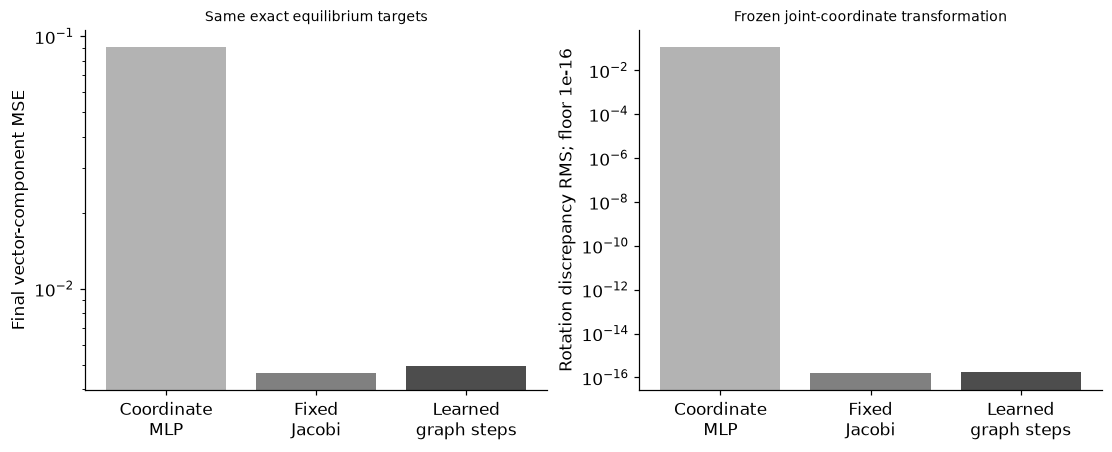

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['final_vector_MSE'] for r in rows],color=['.7','.5','.3']);axes[0].set(yscale='log',xticks=range(3),xticklabels=['Coordinate\nMLP','Fixed\nJacobi','Learned\ngraph steps'],ylabel='Final vector-component MSE',title='Same exact equilibrium targets')
axes[1].bar(range(3),np.maximum([r['rotation_equivariance_RMS'] for r in rows],1e-16),color=['.7','.5','.3']);axes[1].set(yscale='log',xticks=range(3),xticklabels=['Coordinate\nMLP','Fixed\nJacobi','Learned\ngraph steps'],ylabel='Rotation discrepancy RMS; floor 1e-16',title='Frozen joint-coordinate transformation');plt.show()
assert all(np.isfinite(r['final_equilibrium_residual_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_119','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual vector-valued graph propagation', 'learned relaxation with a known physical operator', 'fixed numerical and coordinate-MLP baselines', 'joint rotation reflection translation audits', 'ground-reaction equilibrium'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual vector-valued graph propagation", "learned relaxation with a known physical operator", "fixed numerical and coordinate-MLP baselines", "joint rotation reflection translation audits", "ground-reaction equilibrium"], "elapsed_seconds": 1.247, "example_id": "code_119", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"best_step": 240, "development_MSE": 0.08238714796614363, "model": "Coordinate MLP", "rate": 0.005}, {"best_step": 140, "development_MSE": 0.08247523724065134, "model": "Coordinate MLP", "rate": 0.01}, {"best_step": 300, "development_MSE": 0.004575326159200558, "model": "Learned graph steps", "rate": 0.03}, {"best_step": 300, "development_MSE": 0.0036307750115217472, "model": "Learned graph steps", "rate": 0.1}], "comparisons": [{"development_MSE": 0.08238714796614363, "final_equilibrium_residual_MSE": 0.2182509669054868, "final_vector_MSE": 0.09097882888429051, "model": "Coordinate MLP", "parameters": 242, 